# EN3160 Assignment 02
## Fitting and Alignment

**Name:** Perera H.A.J.I.  
**Index Number:** 230477X  
**Date:** 19-10-2026

**Assignment Repository:** https://github.com/indeepa-05/EN3160-Image-Processing/tree/main/Assignment2

## Task 1 – Sunflower Blob Detection

### Image loading and preprocessing

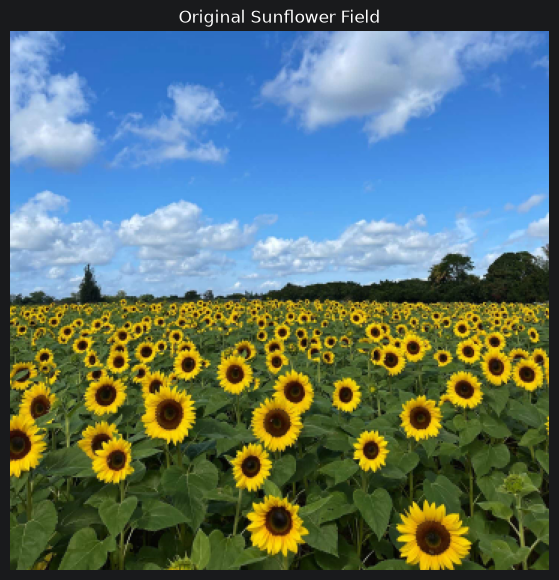

Image dimensions: (360, 360)


In [7]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

# Read at quarter resolution
image = cv.imread("images/the_berry_farms_sunflower_field.jpeg",cv.IMREAD_REDUCED_COLOR_4)
if image is None:
    raise FileNotFoundError("Image not found")
gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
gray = gray.astype(np.float32) / 255.0
plt.figure(figsize=(7, 7))
plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
plt.title("Original Sunflower Field")
plt.axis("off")
plt.show()
print("Image dimensions:", gray.shape)

### Scale-normalized Laplacian of Gaussian

In [8]:
sigmas = np.linspace(1.5, 12, 22)
responses = []
for sigma in sigmas:
    log = ndimage.gaussian_laplace(gray, sigma)
    responses.append(sigma**2 * log)
scale_space = np.array(responses)
print("Sigma range:", sigmas[0], "to", sigmas[-1])
print("Number of scales:", len(sigmas))
print("Scale-space shape:", scale_space.shape)

Sigma range: 1.5 to 12.0
Number of scales: 22
Scale-space shape: (22, 360, 360)


In [9]:
# Scale-space extrema detection
neighborhood = ndimage.maximum_filter(scale_space, size=(3, 7, 7))
# Ignore sky and other upper-image structures
start_row = int(gray.shape[0] * 0.42)
# Select a threshold from positive responses in the field
field = scale_space[:, start_row:, :]
positive = field[field > 0]
threshold = np.percentile(positive, 99)
peaks = ((scale_space == neighborhood) &(scale_space > threshold))
peaks[:, :start_row, :] = False
locations = np.argwhere(peaks)
print("Threshold:", round(float(threshold), 4))
print("Candidate blobs:", len(locations))

Threshold: 0.2272
Candidate blobs: 99


### Scale-space extrema detection

In [10]:
# Convert extrema to circle parameters
candidates = []
for k, y, x in locations:
    candidates.append({"x": int(x),"y": int(y),"sigma": float(sigmas[k]),"radius": float(np.sqrt(2) * sigmas[k]),"score": float(scale_space[k, y, x])})
# Strongest responses first
candidates.sort(key=lambda c: c["score"], reverse=True)
circles = []
for c in candidates:
    if all(np.hypot(c["x"] - p["x"], c["y"] - p["y"])> 0.6 * max(c["radius"], p["radius"])for p in circles):
        circles.append(c)
print("Final circles:", len(circles))

Final circles: 99


In [20]:
# Remove false detections using surrounding yellow petals
hsv = cv.cvtColor(image, cv.COLOR_BGR2HSV)
yellow = cv.inRange(hsv, (13, 80, 65), (40, 255, 255)) > 0
filtered = []
height, width = gray.shape
for c in circles:
    x, y, r = c["x"], c["y"], c["radius"]
    # Ignore circles crossing image boundaries
    if x < r or x >= width-r or y < r or y >= height-r:
        continue
    # Examine the region around the detected centre
    R = int(np.ceil(2.2 * r))
    x1, x2 = max(0, x-R), min(width, x+R+1)
    y1, y2 = max(0, y-R), min(height, y+R+1)
    yy, xx = np.ogrid[y1:y2, x1:x2]
    d2 = (xx-x)**2 + (yy-y)**2
    # Ring where surrounding petals are expected
    ring = (d2 >= (1.05*r)**2) & (d2 <= (2.1*r)**2)
    if yellow[y1:y2, x1:x2][ring].mean() > 0.4:
        filtered.append(c)
circles = filtered
print("Filtered circles:", len(circles))

Filtered circles: 84


### Circle visualization

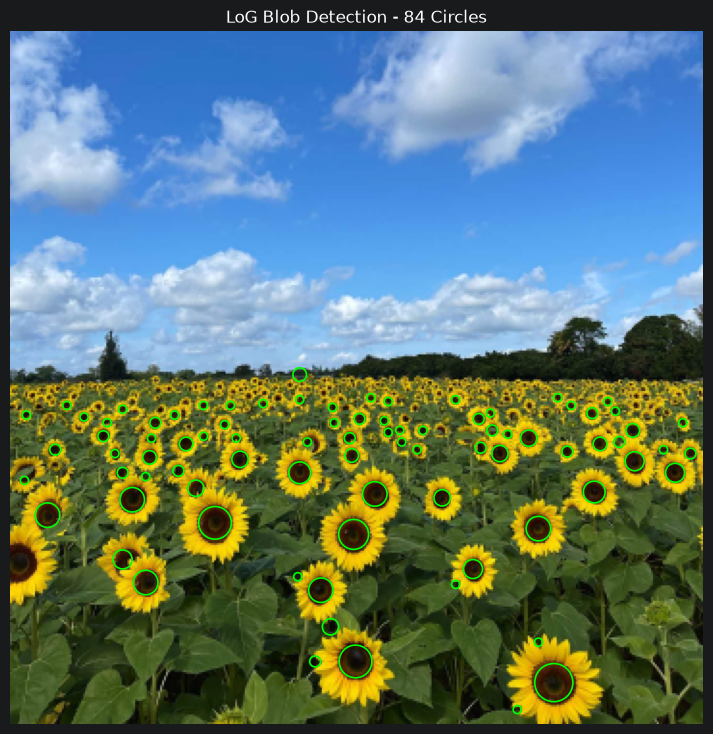

In [21]:
# Visualize detected circles
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
for c in circles:
    ax.add_patch(plt.Circle((c["x"], c["y"]),c["radius"],edgecolor="lime",fill=False,linewidth=1.2))
ax.set_title(f"LoG Blob Detection - {len(circles)} Circles")
ax.axis("off")
plt.show()

### Largest circle parameters and sigma range

Largest Five Detected Circles
 X     Y     Sigma     Radius
282   338   7.00      9.90
106   255   6.00      8.49
179   327   6.00      8.49
178   261   5.50      7.78
189   240   4.50      6.36


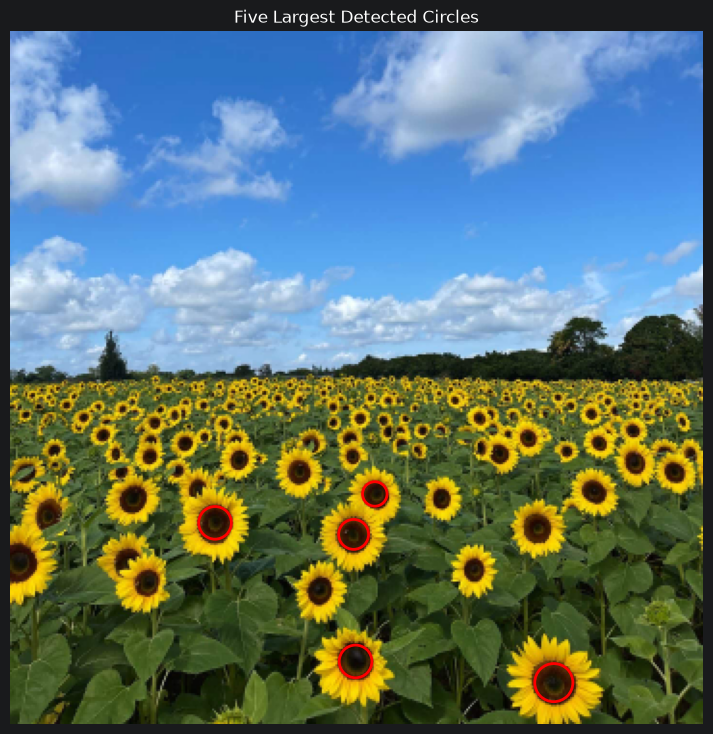

In [22]:
# Report largest five circles
largest = sorted(circles,key=lambda c: c["radius"],reverse=True)[:5]
print("Largest Five Detected Circles")
print(" X     Y     Sigma     Radius")
for c in largest:
    print(
        f"{c['x']:<6}"
        f"{c['y']:<6}"
        f"{c['sigma']:<10.2f}"
        f"{c['radius']:.2f}"
    )
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
for c in largest:
    ax.add_patch(plt.Circle((c["x"], c["y"]),c["radius"],edgecolor="red",fill=False,linewidth=2))
ax.set_title("Five Largest Detected Circles")
ax.axis("off")
plt.show()

### Results and discussion

### Results and Discussion

Sunflower blobs were detected using the scale-normalized Laplacian of Gaussian (LoG) and scale-space extrema detection. The input image was reduced to 360 × 360 pixels, and 22 Gaussian scales ranging from σ = 1.5 to 12.0 were examined. The initial detection identified 99 candidate blobs. A colour based filtering step was then applied to verify the presence of yellow petals surrounding the detected dark centres, reducing the number of detections to 84. The method successfully identified many sunflower centres, particularly those in the foreground. However some smaller or overlapping flowers were missed due to their scale, orientation and proximity to neighbouring flowers. The radius of each detected circle was estimated using \(r=\sqrt{2}\sigma\). The results demonstrate the effectiveness of multiscale LoG detection, while highlighting its limitations in complex scenes containing overlapping objects and background structures.*To be completed after implementing and running this task.*

## Task 2 – RANSAC Line and Circle Fitting

### Generation of noisy data

### Custom RANSAC line estimation

### Removal of line consensus

### Custom RANSAC circle estimation

### Joint visualization

### Effect of fitting the circle first

### Results and discussion

*To be completed after implementing and running this task.*

## Task 3 – Homography and Image Compositing

### Image-pair selection

### Correspondence points

### Homography estimation

### Perspective warping and blending

### Results and discussion

*To be completed after implementing and running this task.*

## Task 4 – PCB Image Alignment

### SIFT feature detection

### Brute-force descriptor matching

### RANSAC homography estimation

### Image alignment

### Difference-image computation

### Comparison across all PCB images

### Interpretation of high differences at raised PCB components

*To be completed after implementing and running this task.*